<a href="https://colab.research.google.com/github/sharasunilkottari-pixel/SDAV_Lab/blob/main/Program4_Exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Previous graphs: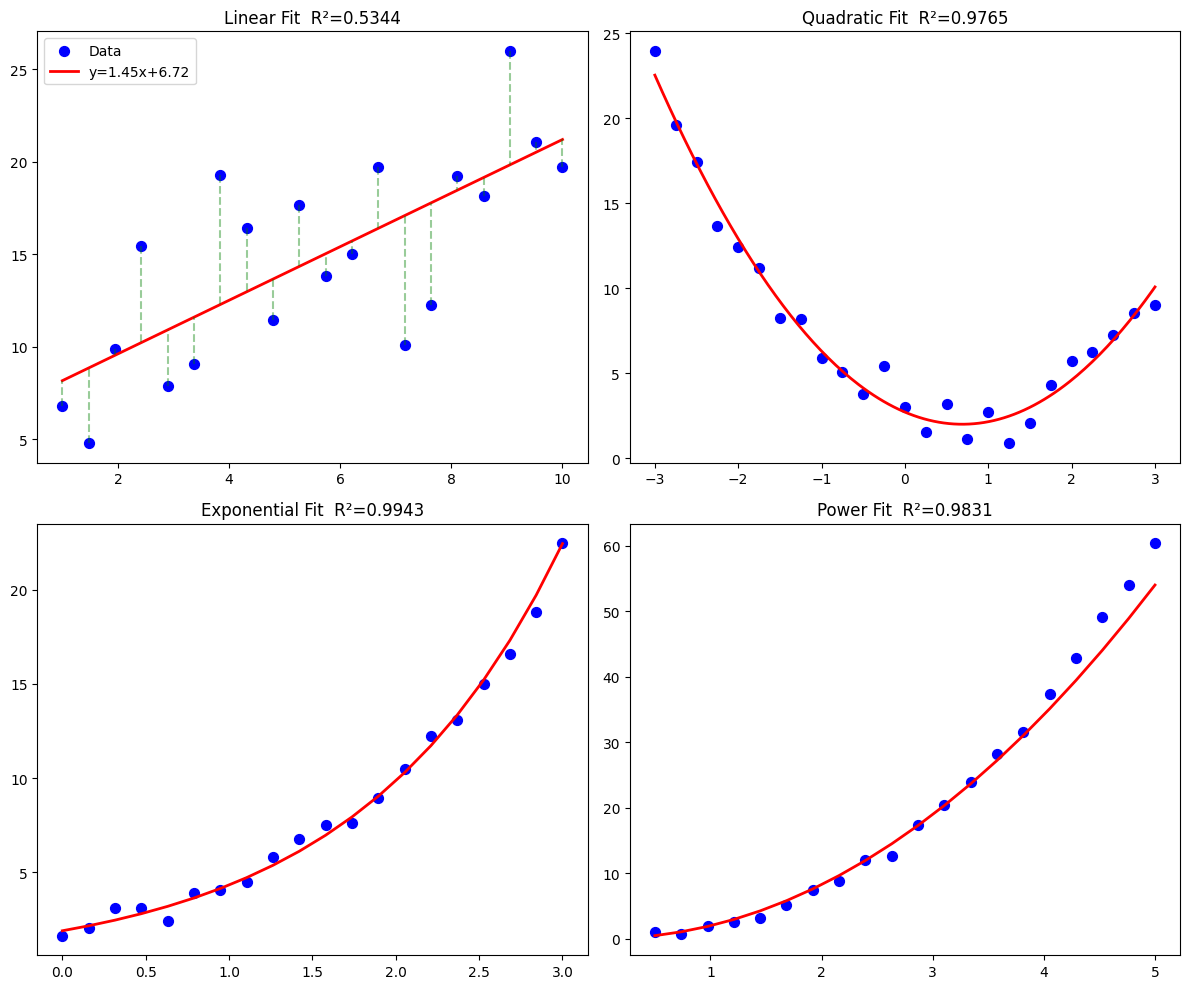

In [43]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [44]:
def r_squared(y, y_hat):
    ss_res = np.sum((y - y_hat)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - ss_res/ss_tot

Question 1:Increase linear noise from 1.5 to 5

Linear: y = 2.7150x + -0.2697
R² = 0.7132


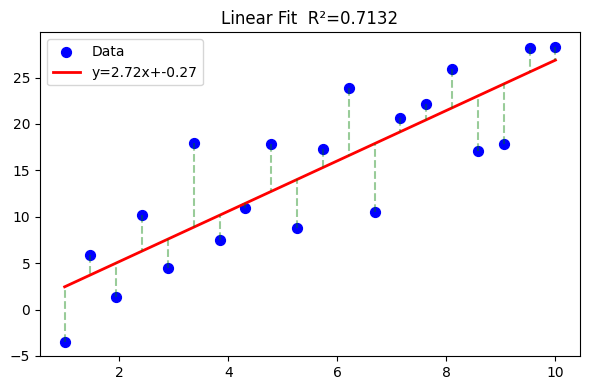

In [51]:
# --- Data ---
x = np.linspace(1, 10, 20)
y = 2.5*x + 1.8 + np.random.normal(0, 5, 20)

# --- 1. LINEAR FIT: Normal Equations ---
n = len(x)
a = (n*np.sum(x*y) - np.sum(x)*np.sum(y)) / (n*np.sum(x**2) - np.sum(x)**2)
b = (np.sum(y) - a*np.sum(x)) / n
print(f'Linear: y = {a:.4f}x + {b:.4f}')
y_lin = a*x + b
print(f'R² = {r_squared(y, y_lin):.4f}')


# --- VISUALIZATION ---
fig, axes = plt.subplots(figsize=(6, 4))

# Linear
xf = np.linspace(x.min(), x.max(), 200)
axes.scatter(x, y, color='blue', s=50, label='Data')
axes.plot(xf, a*xf+b, 'r-', lw=2, label=f'y={a:.2f}x+{b:.2f}')
for xi,yi,yp in zip(x,y,y_lin):
    axes.plot([xi,xi],[yi,yp],'g--',alpha=0.4)
axes.set_title(f'Linear Fit  R²={r_squared(y,y_lin):.4f}')
axes.legend()
plt.tight_layout(); plt.show()


Question 2:Reduce linear noise from 1.5 to 0

Linear: y = 2.5000x + 1.8000
R² = 1.0000


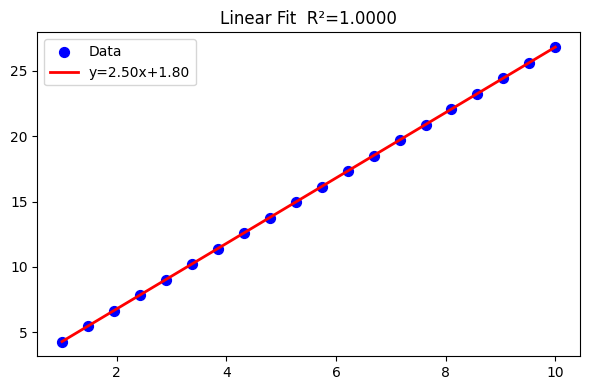

In [52]:
x = np.linspace(1, 10, 20)
y = 2.5*x + 1.8 + np.random.normal(0, 0, 20)

# --- 1. LINEAR FIT: Normal Equations ---
n = len(x)
a = (n*np.sum(x*y) - np.sum(x)*np.sum(y)) / (n*np.sum(x**2) - np.sum(x)**2)
b = (np.sum(y) - a*np.sum(x)) / n
print(f'Linear: y = {a:.4f}x + {b:.4f}')
y_lin = a*x + b
print(f'R² = {r_squared(y, y_lin):.4f}')

# --- VISUALIZATION ---
fig, axes = plt.subplots(figsize=(6,4))

# Linear
xf = np.linspace(x.min(), x.max(), 200)
axes.scatter(x, y, color='blue', s=50, label='Data')
axes.plot(xf, a*xf+b, 'r-', lw=2, label=f'y={a:.2f}x+{b:.2f}')
for xi,yi,yp in zip(x,y,y_lin):
    axes.plot([xi,xi],[yi,yp],'g--',alpha=0.4)
axes.set_title(f'Linear Fit  R²={r_squared(y,y_lin):.4f}')
axes.legend()
plt.tight_layout(); plt.show()

Question 3:Change polynomial degree from 2 to 1

Quadratic: y = -0.0863x² + -0.5702x + 3.3144
R² = 0.5983


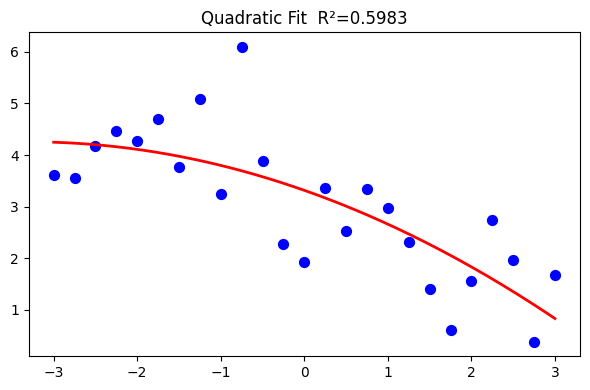

In [53]:
x2 = np.linspace(-3, 3, 25)
y2 = 1.5*x2**1 - 2*x2 + 3 + np.random.normal(0,1,25)
c2 = np.polyfit(x2, y2, 2)
print(f'Quadratic: y = {c2[0]:.4f}x² + {c2[1]:.4f}x + {c2[2]:.4f}')
print(f'R² = {r_squared(y2, np.polyval(c2,x2)):.4f}')

# --- VISUALIZATION ---
fig, axes = plt.subplots(figsize=(6,4))
xf2 = np.linspace(x2.min(), x2.max(), 200)
axes.scatter(x2, y2, color='blue', s=50)
axes.plot(xf2, np.polyval(c2,xf2), 'r-', lw=2)
axes.set_title(f'Quadratic Fit  R²={r_squared(y2,np.polyval(c2,x2)):.4f}')
plt.tight_layout(); plt.show()

Question 4:Change polynomial degree from 2 to 15

Quadratic: y = -0.1245x² + 2089066.5839x + 3.6864
R² = 0.3551


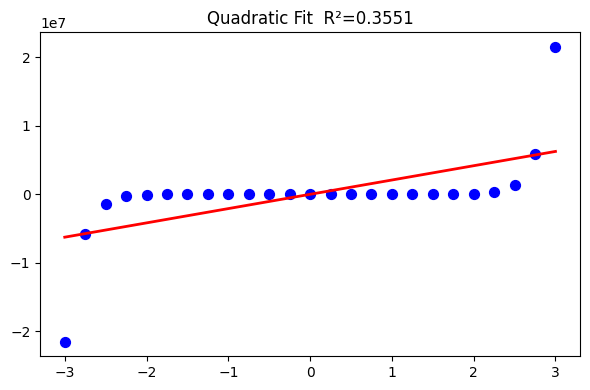

In [54]:
x2 = np.linspace(-3, 3, 25)
y2 = 1.5*x2**15 - 2*x2 + 3 + np.random.normal(0,1,25)
c2 = np.polyfit(x2, y2, 2)
print(f'Quadratic: y = {c2[0]:.4f}x² + {c2[1]:.4f}x + {c2[2]:.4f}')
print(f'R² = {r_squared(y2, np.polyval(c2,x2)):.4f}')

# --- VISUALIZATION ---
fig, axes = plt.subplots(figsize=(6,4))
xf2 = np.linspace(x2.min(), x2.max(), 200)
axes.scatter(x2, y2, color='blue', s=50)
axes.plot(xf2, np.polyval(c2,xf2), 'r-', lw=2)
axes.set_title(f'Quadratic Fit  R²={r_squared(y2,np.polyval(c2,x2)):.4f}')
plt.tight_layout(); plt.show()

Question 5:Change exponenetial coefficient from 0.8 t0 -0.8 and changing the noise from 0.5 to 0.02

Exponential: y = 2.0042•e^(-0.8070x)
R² = 0.9993


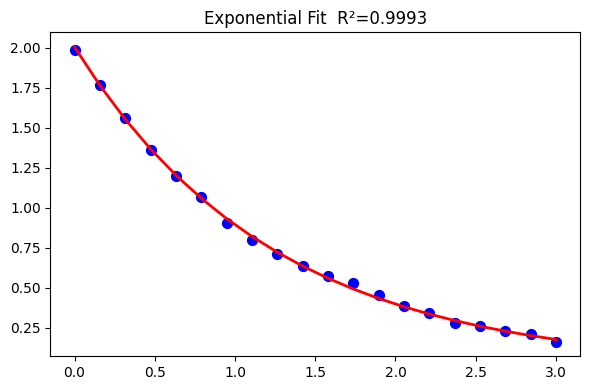

In [61]:
#Linearize ln(y) = ln(a) + bx
x3 = np.linspace(0, 3, 20)
y3 = 2.0*np.exp((-0.8)*x3) + np.random.normal(0, 0.02, 20)
log_y3  = np.log(y3)
ce = np.polyfit(x3, log_y3, 1)
a_e, b_e = np.exp(ce[1]), ce[0]
print(f'Exponential: y = {a_e:.4f}•e^({b_e:.4f}x)')
y_exp = a_e * np.exp(b_e * x3)
print(f'R² = {r_squared(y3, y_exp):.4f}')

# --- VISUALIZATION ---
fig, axes = plt.subplots(figsize=(6,4))
axes.scatter(x3, y3, color='blue', s=50)
axes.plot(x3, y_exp, 'r-', lw=2)
axes.set_title(f'Exponential Fit  R²={r_squared(y3,y_exp):.4f}')
plt.tight_layout(); plt.show()

Question 6:Change power exponent from 2.3 to 1

Power: y = 1.2813•x^1.1520
R² = 0.9395


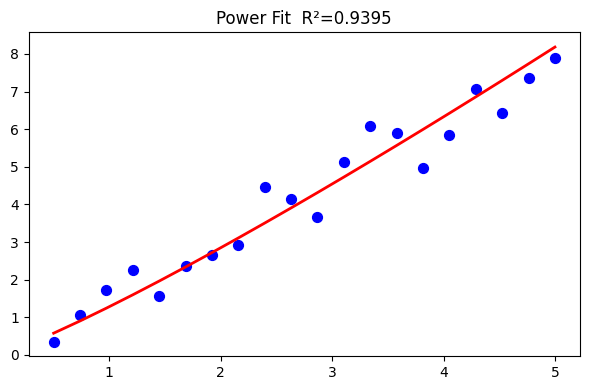

In [56]:
#Linearize ln(y) = ln(a) + b•ln(x)
x4 = np.linspace(0.5, 5, 20)
y4 = 1.5*x4**1 + np.random.normal(0, 0.5, 20)
cp = np.polyfit(np.log(x4), np.log(y4), 1)
a_p, b_p = np.exp(cp[1]), cp[0]
print(f'Power: y = {a_p:.4f}•x^{b_p:.4f}')
y_pow = a_p * x4**b_p
print(f'R² = {r_squared(y4, y_pow):.4f}')

# --- VISUALIZATION ---
fig, axes = plt.subplots(figsize=(6,4))
axes.scatter(x4, y4, color='blue', s=50)
axes.plot(x4, y_pow, 'r-', lw=2)
axes.set_title(f'Power Fit  R²={r_squared(y4,y_pow):.4f}')
plt.tight_layout(); plt.show()